# Multiple Linear Regression

Julia Welter, Pedro Pacheco, Pedro K. Albuquerque, and Tiago Rosa

A study of the relationship between house price, property size, and number of bedrooms.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')

try:
    from sklearn.linear_model import LinearRegression
    SKLEARN_OK = True
except Exception:
    SKLEARN_OK = False

In [2]:
COLUNAS = ['tamanho', 'quartos', 'preco']

def carregar_base():
    csv_path = Path('data/housing_data.csv')
    mat_path = Path('data/housing_data.mat')

    if csv_path.exists():
        return pd.read_csv(csv_path, header=None, names=COLUNAS)

    if mat_path.exists():
        from scipy.io import loadmat
        mat = loadmat(mat_path)
        for valor in mat.values():
            if isinstance(valor, np.ndarray) and valor.ndim == 2 and valor.shape[1] >= 3:
                return pd.DataFrame(valor[:, :3], columns=COLUNAS)

    raise FileNotFoundError('Neither data/housing_data.csv nor data/housing_data.mat was found.')

def montar_X_y(base):
    x_base = base[['tamanho', 'quartos']].to_numpy(dtype=float)
    y = base['preco'].to_numpy(dtype=float).reshape(-1, 1)
    intercepto = np.ones((x_base.shape[0], 1))
    x = np.hstack((intercepto, x_base))
    return x_base, x, y

def regmultipla(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    return np.linalg.solve(X.T @ X, X.T @ y)

def calcular_theta(base):
    _, x, y = montar_X_y(base)
    return regmultipla(x, y)

def calcular_correlacoes(base):
    preco = base['preco'].to_numpy(dtype=float)
    corr_tamanho = float(np.corrcoef(base['tamanho'], preco)[0, 1])
    corr_quartos = float(np.corrcoef(base['quartos'], preco)[0, 1])
    return corr_tamanho, corr_quartos

## Loading the Data

In [3]:
base = carregar_base()
print(f'Total examples: {len(base)}')
base.head()

Total examples: 47


,tamanho,quartos,preco
0,2104,3,399900.0
1,1600,3,329900.0
2,2400,3,369000.0
3,1416,2,232000.0
4,3000,4,539900.0


## Statistical Analysis

In [4]:
describe = base.describe()
media_preco = base['preco'].mean()
indice_menor_casa = base['tamanho'].idxmin()
preco_menor_casa = base.loc[indice_menor_casa, 'preco']
indice_mais_cara = base['preco'].idxmax()
quartos_mais_cara = int(base.loc[indice_mais_cara, 'quartos'])

print(f'Media de preco das casas: {media_preco:.2f}')
print(f'Preco da menor casa: {preco_menor_casa:.2f}')
print(f'Quartos da casa mais cara: {quartos_mais_cara}')
describe

Media de preco das casas: 340412.77
Preco da menor casa: 179900.00
Quartos da casa mais cara: 5


,tamanho,quartos,preco
count,47.000000,47.000000,47.000000
mean,2000.680851,3.170213,340412.765957
std,794.702354,0.760982,125039.911223
min,852.000000,1.000000,169900.000000
25%,1432.000000,3.000000,249900.000000
50%,1888.000000,3.000000,299900.000000
75%,2269.000000,4.000000,384450.000000
max,4478.000000,5.000000,699900.000000


## Building X and y

In [5]:
x_base, x, y = montar_X_y(base)
print(f'Shape de X_base: {x_base.shape}')
print(f'Shape de X: {x.shape}')
print(f'Shape de y: {y.shape}')

display(base[['tamanho', 'quartos']].head())
display(base.assign(intercepto=1)[['intercepto', 'tamanho', 'quartos']].head())
display(base[['preco']].head())

Shape de X_base: (47, 2)
Shape de X: (47, 3)
Shape de y: (47, 1)


,tamanho,quartos
0,2104,3
1,1600,3
2,2400,3
3,1416,2
4,3000,4


,intercepto,tamanho,quartos
0,1,2104,3
1,1,1600,3
2,1,2400,3
3,1,1416,2
4,1,3000,4


,preco
0,399900.0
1,329900.0
2,369000.0
3,232000.0
4,539900.0


## Correlation and Simple Linear Regression

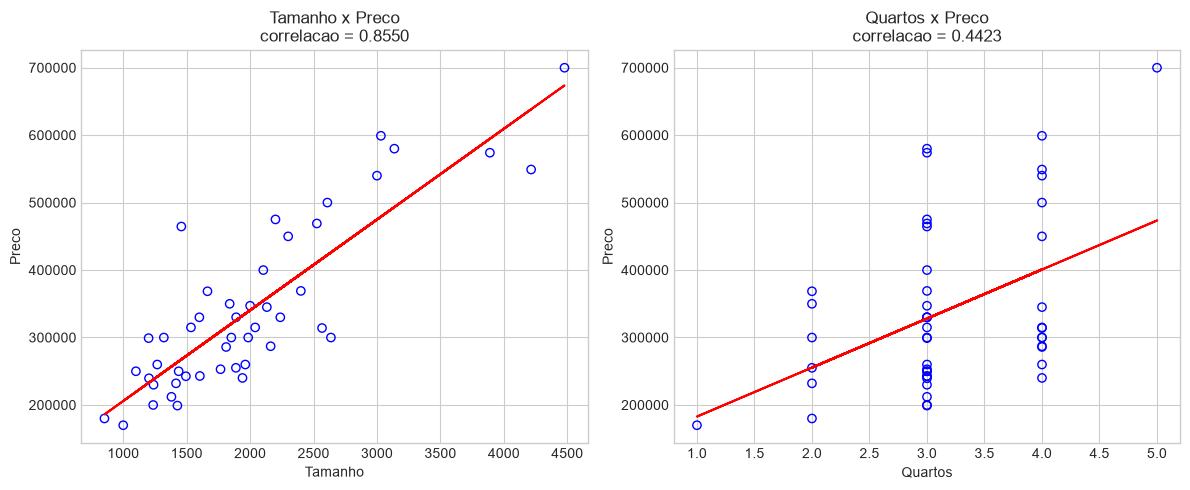

In [6]:
tamanho = base['tamanho'].to_numpy(dtype=float)
quartos = base['quartos'].to_numpy(dtype=float)
preco = base['preco'].to_numpy(dtype=float)

corr_tamanho, corr_quartos = calcular_correlacoes(base)
ang_tamanho, lin_tamanho = np.polyfit(tamanho, preco, 1)
ang_quartos, lin_quartos = np.polyfit(quartos, preco, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(tamanho, preco, edgecolors='blue', facecolors='none')
axes[0].plot(tamanho, lin_tamanho + ang_tamanho * tamanho, 'r-')
axes[0].set_title(f'Tamanho x Preco\ncorrelacao = {corr_tamanho:.4f}')
axes[0].set_xlabel('Tamanho')
axes[0].set_ylabel('Preco')

axes[1].scatter(quartos, preco, edgecolors='blue', facecolors='none')
axes[1].plot(quartos, lin_quartos + ang_quartos * quartos, 'r-')
axes[1].set_title(f'Quartos x Preco\ncorrelacao = {corr_quartos:.4f}')
axes[1].set_xlabel('Quartos')
axes[1].set_ylabel('Preco')

plt.tight_layout()
plt.show()

## Multiple Regression

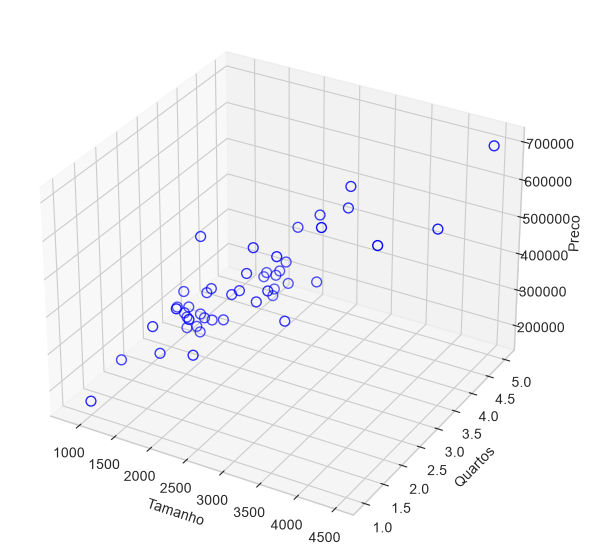

beta0 (intercepto): 89597.77
beta1 (tamanho):    139.210635
beta2 (quartos):    -8737.915420
Equacao: preco = 89597.77 + (139.210635 * tamanho) + (-8737.915420 * quartos)


In [7]:
theta = calcular_theta(base)
beta0, beta1, beta2 = theta.flatten()

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(tamanho, quartos, preco, edgecolors='blue', facecolors='none', s=50)
ax.set_xlabel('Tamanho')
ax.set_ylabel('Quartos')
ax.set_zlabel('Preco')
plt.show()

print(f'beta0 (intercepto): {beta0:.2f}')
print(f'beta1 (tamanho):    {beta1:.6f}')
print(f'beta2 (quartos):    {beta2:.6f}')
print(f'Equacao: preco = {beta0:.2f} + ({beta1:.6f} * tamanho) + ({beta2:.6f} * quartos)')

## Regression Line in a 3D Plot

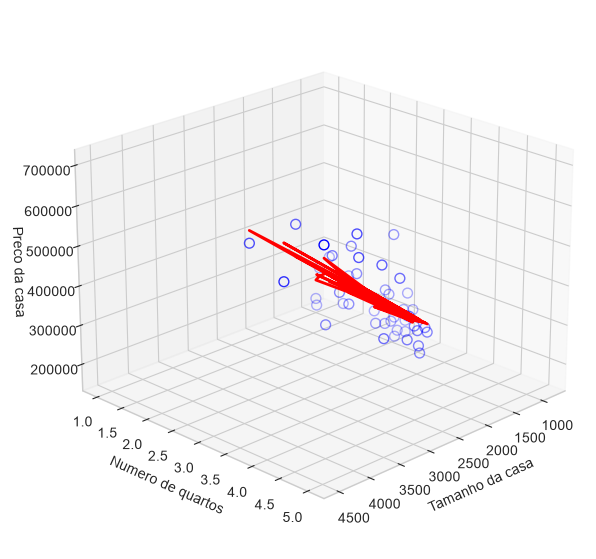

In [8]:
y_reg = beta0 + beta1 * tamanho + beta2 * quartos

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(tamanho, quartos, preco, edgecolors='blue', facecolors='none', s=50)
ax.plot(tamanho, quartos, y_reg, 'r-', linewidth=2)
ax.set_xlabel('Tamanho da casa')
ax.set_ylabel('Numero de quartos')
ax.set_zlabel('Preco da casa')
ax.view_init(elev=22, azim=45)
plt.show()

## Regression Plane and Correlations

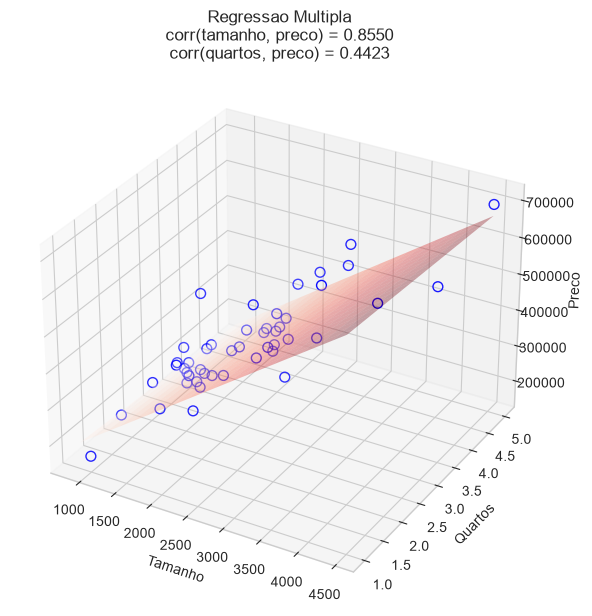

In [9]:
grade_tamanho = np.linspace(tamanho.min(), tamanho.max(), 20)
grade_quartos = np.linspace(quartos.min(), quartos.max(), 20)
malha_tamanho, malha_quartos = np.meshgrid(grade_tamanho, grade_quartos)
malha_preco = beta0 + beta1 * malha_tamanho + beta2 * malha_quartos

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(tamanho, quartos, preco, edgecolors='blue', facecolors='none', s=50)
ax.plot_surface(malha_tamanho, malha_quartos, malha_preco, alpha=0.35, cmap='Reds')
ax.set_xlabel('Tamanho')
ax.set_ylabel('Quartos')
ax.set_zlabel('Preco')
ax.set_title(
    'Regressao Multipla\n'
    f'corr(tamanho, preco) = {corr_tamanho:.4f}\n'
    f'corr(quartos, preco) = {corr_quartos:.4f}'
)
plt.show()

## Predictions

In [10]:
preco_3_quartos = float(np.array([1, 1650, 3]) @ theta.flatten())
preco_2_quartos = float(np.array([1, 1650, 2]) @ theta.flatten())
preco_4_quartos = float(np.array([1, 1650, 4]) @ theta.flatten())

print(f'3 quartos: {preco_3_quartos:.2f}')
print(f'2 quartos: {preco_2_quartos:.2f}')
print(f'4 quartos: {preco_4_quartos:.2f}')
print('Mantendo o tamanho fixo, a variacao segue o sinal do coeficiente associado a quartos.')

3 quartos: 293081.57
2 quartos: 301819.48
4 quartos: 284343.65
Mantendo o tamanho fixo, a variacao segue o sinal do coeficiente associado a quartos.


## Comparison with scikit-learn

In [11]:
if SKLEARN_OK:
    modelo = LinearRegression()
    modelo.fit(x_base, y)
    theta_sklearn = np.array([
        modelo.intercept_.item(),
        modelo.coef_.flatten()[0],
        modelo.coef_.flatten()[1],
    ])
    print('Equacao normal:')
    print(theta.flatten())
    print('Scikit-learn:')
    print(theta_sklearn)
else:
    print('scikit-learn nao esta instalado neste ambiente.')

Equacao normal:
[89597.765961     139.21063465 -8737.91542019]
Scikit-learn:
[89597.765961     139.21063465 -8737.91542019]
